Test the slab model with 2 islands. Fig.15 (a):
$$
\begin{align*}
&m_1=m_2=1\;,\;n_1=-n_2=1\\
&\delta_1=\delta_2 =0.05\\
&\iota'=2
\end{align*}
$$

In [2]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
from fields.slab_bfield_two_pert import SlabBfieldTwoPert
from pyoculus.maps import ToroidalBfieldSection
from pyoculus.solvers import PoincarePlot, FixedPoint, Manifold
import matplotlib.pyplot as plt

#### Create the magnetic field:

In [3]:
field = SlabBfieldTwoPert(
    m1=1,
    n1=1,
    delta1=0.05,
    m2=1,
    n2=-1,
    delta2=0.05,
    iota_prime=2.0,
    x0=1.0,
)

xs1 = field.x0 + field.n1 / (field.iota_prime * field.m1)
xs2 = field.x0 + field.n2 / (field.iota_prime * field.m2)

print("The islands will be situated at x_s =", xs1, xs2)

The islands will be situated at x_s = 1.5 0.5


#### Create the map:

In [4]:
map = ToroidalBfieldSection(field, domain=[(0, 2), (0, 2*np.pi)])

#### Create Poincaré plot:

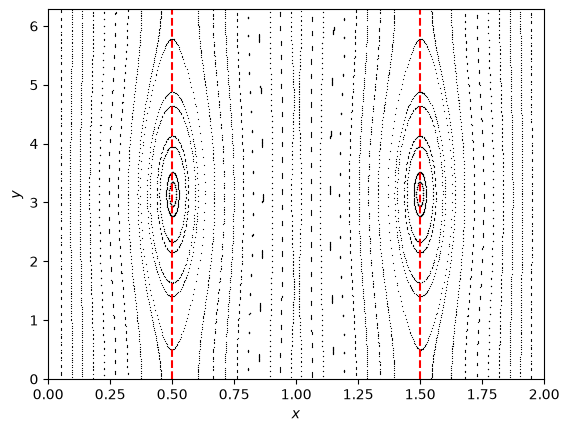

In [5]:
pplot = PoincarePlot.with_linspace(
    map,
    np.array([0.05, np.pi]),
    np.array([1.95, np.pi]),
    npts=50
)

# Follow each initial condition for 200 crossings
pplot.compute(npts=150)

# Plot directly in (x,y) coordinates
fig, ax = pplot.plot(plottype=None) # plottypeNone to directly plot in the coordinates of the map

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_xlim(0, 2)
ax.set_ylim(0, 2*np.pi)

ax.axvline(
    xs1,
    linestyle="--",
    label=rf"$x_s1={xs1:.3f}$",
    color="r"
)
ax.axvline(
    xs2,
    linestyle="--",
    label=rf"$x_s2={xs2:.3f}$",
    color="r"
)
plt.show()

#### Find fixed points:

(<Figure size 640x480 with 1 Axes>, <Axes: >)

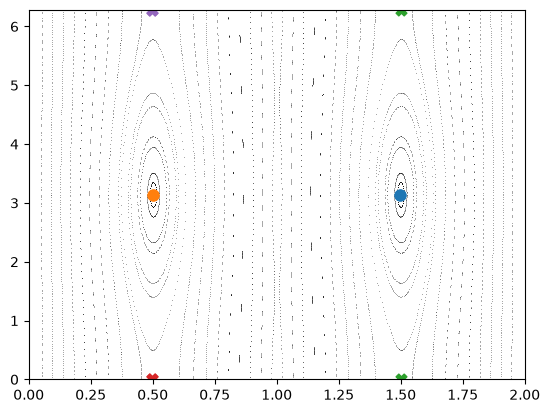

In [6]:
fig, ax = pplot.plot(
    marker=".",
    s=0.5,
    xlim=[0, 2],
    ylim=[0, 2*np.pi],
    plottype=None
)


fp = FixedPoint(map)

# Elliptic fixed points / O-points:
result = fp.find_with_iota(
    n = field.n1,
    m = field.m1,
    guess = np.array([1.4, 3]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find_with_iota(
    n = field.n2,
    m = field.m2,
    guess = np.array([1.4, 3]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

# Hyperbolic fixed points / X-points:
result = fp.find_with_iota(
    n = field.n1,
    m = field.m1,
    guess = np.array([1.4, 0.2]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find_with_iota(
    n = field.n2,
    m = field.m2,
    guess = np.array([0.4, 0.2]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find_with_iota(
    n = field.n2,
    m = field.m2,
    guess = np.array([0.6, 6.]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

In this case, the X-points have been found separately. All the fixed points have been found with ```find_with_iota()```.

#### Find manifolds

In [7]:
fp1 = FixedPoint(map)
fp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([1.4, 0.2]), method="scipy.root")   

fp2 = FixedPoint(map)
fp2.find_with_iota(n = field.n1, m = field.m1, guess = fp1.coords[1], method="scipy.root")  

fp3 = FixedPoint(map)
fp3.find_with_iota(n = field.n2, m = field.m2, guess = np.array([0.5, 0.2]), method="scipy.root")  

fp4 = FixedPoint(map)
fp4.find_with_iota(n = field.n2, m = field.m2, guess = np.array([0.6, 6]), method="scipy.root")  

ofp1 = FixedPoint(map)
ofp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([1.4, 3]), method="scipy.root")

ofp2 = FixedPoint(map)
ofp2.find_with_iota(n = field.n2, m = field.m2, guess = np.array([0.4, 3]), method="scipy.root")

In [8]:
manifold1 = Manifold(
    map, fp1, fp2,
    dir1=ofp1.coords[0] - fp1.coords[0],
    dir2=ofp1.coords[0] - fp2.coords[0]
)
manifold2 = Manifold(
    map, fp1, fp2,
    dir1=ofp1.coords[0] - fp1.coords[0],
    dir2=ofp1.coords[0] - fp2.coords[0],
    first_stable=False
)
manifold3 = Manifold(
    map, fp3, fp4,
    dir1=ofp2.coords[0] - fp3.coords[0],
    dir2=ofp2.coords[0] - fp4.coords[0]
)
manifold4 = Manifold(
    map, fp3, fp4,
    dir1=ofp2.coords[0] - fp3.coords[0],
    dir2=ofp2.coords[0] - fp4.coords[0],
    first_stable=False
)

In [9]:
manifold1.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
stable1, unstable1 = manifold1.compute_adaptive()

manifold2.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
stable2, unstable2 = manifold2.compute_adaptive()

manifold3.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
stable3, unstable3 = manifold3.compute_adaptive()

manifold4.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
stable4, unstable4 = manifold4.compute_adaptive()

c:\Users\mirei\OneDrive - epfl.ch\MA3\SdS\local\.venv\Lib\site-packages\scipy\integrate\_ode.py:356: ComplexWarning: Casting complex values to real discards the imaginary part
  self._y = asarray(y, self._integrator.scalar).copy()
c:\Users\mirei\OneDrive - epfl.ch\MA3\SdS\local\slab_model\fields\slab_bfield_two_pert.py:56: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.array([Bx, By, Bz], dtype=np.float64)
Shifted clinic by (0, -1) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iter

c:\Users\mirei\OneDrive - epfl.ch\MA3\SdS\local\.venv\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\mirei\OneDrive - epfl.ch\MA3\SdS\local\.venv\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


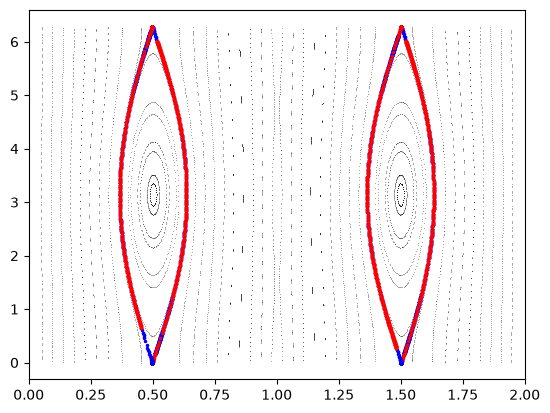

In [10]:
fig, ax = pplot.plot(marker=".", s=0.5, xlim=[.0, 2.], plottype=None)

ax.plot(stable1[:, 0], stable1[:, 1], color="blue", label="Stable", marker=".", markersize=3, linestyle="")
ax.plot(unstable1[:, 0], unstable1[:, 1], color="red", label="Unstable", marker=".", markersize=3, linestyle="")

ax.plot(stable2[:, 0], stable2[:, 1], color="blue", label="Stable", marker=".", markersize=3, linestyle="")
ax.plot(unstable2[:, 0], unstable2[:, 1], color="red", label="Unstable", marker=".", markersize=3, linestyle="")

ax.plot(stable4[:, 0], stable4[:, 1], color="blue", label="Stable", marker=".", markersize=3, linestyle="")
ax.plot(unstable4[:, 0], unstable4[:, 1], color="red", label="Unstable", marker=".", markersize=3, linestyle="")

ax.plot(stable3[:, 0], stable3[:, 1], color="blue", label="Stable", marker=".", markersize=3, linestyle="")
ax.plot(unstable3[:, 0], unstable3[:, 1], color="red", label="Unstable", marker=".", markersize=3, linestyle="")

# ax.legend()
plt.show()